# IND320 project work, part 4: Machine learning

This notebook continues the earlier IND320 projects. It covers exchange rates, the app structure, weather comparisons and a simple forecast for reservoir filling. The app and notebook use shared functions.

## Sketch of the app

This sketch shows how I organised the pages.

```text
Explore: home, area map, reservoir data, power transfers and exchange rates
Analysis: reservoir patterns, weather outliers and correlation
Forecast: reservoir forecast
```

The electricity area can be shared in the sidebar. Dates and analysis settings can be selected on the relevant pages. The map shows monthly reservoir filling, spot prices for a selected day, or weather for a selected day or month in electricity areas. The weather colours use five sampled locations in each area. The selected area, final history month, history length and forecast horizon are shared with the forecast. I can also display NVE region outlines. The map uses NVE electricity-area polygons and also offers NVE region outlines. A separate table shows VASS statistics, alongside NVE's reference map of the three water reservoir areas. The interactive map uses electricity-area boundaries.

## Preparing the project environment

I keep the functions in separate files so that I can use the same calculations in the app.

In [1]:
# Find the project folder so the same utility functions work from the notebook.
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "streamlit_app.py").exists():
    PROJECT_DIR = PROJECT_DIR.parent
sys.path.insert(0, str(PROJECT_DIR))

from utils.currency_utils import load_exchange_rates
from utils.data_utils import load_reservoirs
from utils.forecast_utils import monthly_exchange_rates, monthly_reservoir, forecast_reservoir

## Exchange rates from Norges Bank

The function downloads business-day rates for EUR and USD. The values show Norwegian kroner for one euro or one US dollar. I use 2024 here so the example can be repeated.

In [2]:
# A fixed year makes this download easy to repeat and compare.
rates_2024 = load_exchange_rates("2024-01-01", "2024-12-31")
print("Observations per currency:")
display(rates_2024.groupby("currency").size().rename("days"))
display(rates_2024.head())

Observations per currency:


currency
EUR    251
USD    251
Name: days, dtype: int64

,date,currency,nok_per_unit
0,2024-01-02,EUR,11.2815
1,2024-01-02,USD,10.2971
2,2024-01-03,EUR,11.3200
3,2024-01-03,USD,10.3672
4,2024-01-04,EUR,11.2845


## Dates and time zones

- **NVE:** the reservoir series used here has weekly dates, not hourly timestamps. I group the dates into calendar months.
- **ENTSO-E:** the stored transfer timestamps are in UTC. The data is grouped by the Norwegian calendar after conversion to `Europe/Oslo`. The app converts UTC to local time when displaying the transfer plot.
- **Open-Meteo:** the API's ISO timestamps use a fixed offset and do not follow daylight-saving changes within a response. I now request weather in GMT/UTC, so the hourly values have one clear timeline. For hourly comparisons with local data, I can convert UTC to `Europe/Oslo` after downloading. The weather month is a UTC calendar month, so its boundary can differ slightly from a Norwegian local month.
- **Norges Bank:** exchange rates have business-day dates, not hourly timestamps. I use monthly averages rather than inventing an hourly rate.

The example shows the Norwegian clock change in spring 2024. After 01:30 UTC the local clock has moved from 01:30 to 03:30. UTC itself does not skip an hour. [Open-Meteo API documentation](https://open-meteo.com/en/docs/historical-weather-api) · [Norges Bank data guide](https://www.norges-bank.no/en/topics/Statistics/open-data/guide-data-warehouse/)

In [3]:
# UTC stays continuous while the Norwegian local clock changes.
times = pd.to_datetime(["2024-03-31 00:30", "2024-03-31 01:30"], utc=True)
display(pd.DataFrame({"UTC": times.strftime("%Y-%m-%d %H:%M %Z"),
                      "Norwegian time": times.tz_convert("Europe/Oslo").strftime("%Y-%m-%d %H:%M %Z")}))

,UTC,Norwegian time
0,2024-03-31 00:30 UTC,2024-03-31 01:30 CET
1,2024-03-31 01:30 UTC,2024-03-31 03:30 CEST


## Monthly reservoir data for NO3

The reservoir data is weekly. A monthly average gives fewer observations and makes the first forecasting example quicker to run. I exclude the current incomplete month.

Ten years gives roughly 520 weekly observations but only 120 monthly averages. Monthly data makes it quick to compare settings and matches the requested horizon of months. The trade-off is that short weekly changes are smoothed out.

In [4]:
# Stop at October so the example uses the same completed months when rerun.
reservoirs = load_reservoirs()
no3 = monthly_reservoir(reservoirs, "NO3").loc[:"2026-10-01"]
print(f"NO3: {len(no3)} complete months, from {no3.index.min():%Y-%m} to {no3.index.max():%Y-%m}.")
display(no3.tail().to_frame())

NO3: 382 complete months, from 1995-01 to 2026-10.


,fill_percent
date,
2026-06-01,50.257950
2026-07-01,57.065369
2026-08-01,61.566397
2026-09-01,67.026628
2026-10-01,72.164537


## Comparing a few River model settings

The model compares the latest reservoir pattern with similar earlier months. I first compare two choices for previous months and two choices for the number of similar months. The last 12 months are kept separate while I choose these settings.

The comparison below uses the previous 12 months for validation. It predicts each month before learning its actual value. The error is the mean absolute error in percentage points. This is a small first comparison for NO3, not proof that one setting is best for every area.

In [5]:
# Keep the final year separate from the setting comparison.
from time import perf_counter
start_time = perf_counter()
tuning_data = no3.iloc[:-12]
comparisons = []
for lags in (3, 12):
    for neighbours in (3, 5):
        _, _, scores = forecast_reservoir(tuning_data, lags=lags, n_neighbors=neighbours)
        comparisons.append({"Previous months": lags, "Similar months": neighbours,
                            "Validation MAE (percentage points)": round(scores["mae"], 2)})
settings = pd.DataFrame(comparisons).sort_values("Validation MAE (percentage points)")
display(settings.reset_index(drop=True))
print(f"Four comparisons took {perf_counter() - start_time:.2f} seconds (excluding downloads).")

,Previous months,Similar months,Validation MAE (percentage points)
0,12,3,14.63
1,3,3,15.13
2,3,5,15.68
3,12,5,15.91


Four comparisons took 0.02 seconds (excluding downloads).


## Testing and making a forecast

I use the best setting from the comparison for a separate test on the final 12 observed months. This test also predicts one month at a time before learning the actual result. The future forecast is different: each predicted month is used to estimate the following month, so errors can build up.

In [6]:
# Use the best setting from the earlier comparison, not from the final test.
best = settings.iloc[0]
forecast, test, summary = forecast_reservoir(
    no3, horizon=3, lags=int(best["Previous months"]),
    n_neighbors=int(best["Similar months"]),
)
print(f"One-month-ahead test MAE: {summary['mae']:.2f} percentage points.")
display(test.tail())
display(forecast)

One-month-ahead test MAE: 7.41 percentage points.


,date,actual,predicted
7,2026-06-01,50.257950,62.233770
8,2026-07-01,57.065369,75.825578
9,2026-08-01,61.566397,70.981768
10,2026-09-01,67.026628,74.197750
11,2026-10-01,72.164537,80.277564


,date,predicted
0,2026-11-01,78.554658
1,2026-12-01,66.181912
2,2027-01-01,55.953074


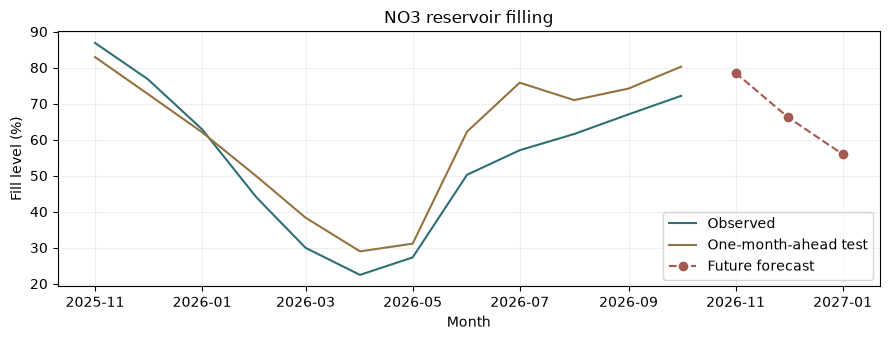

In [7]:
# Plot the test and future forecast separately because they use different information.
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(test["date"], test["actual"], label="Observed", color="#2F6F73")
ax.plot(test["date"], test["predicted"], label="One-month-ahead test", color="#947340")
ax.plot(forecast["date"], forecast["predicted"], "o--", label="Future forecast", color="#A45A52")
ax.set(title="NO3 reservoir filling", xlabel="Month", ylabel="Fill level (%)")
ax.legend(); ax.grid(alpha=0.2); fig.tight_layout()
plt.show()

## Checking forecasts several months ahead

The one-month test uses each newly observed value before the next prediction. To check the actual recursive forecast, I also start a three-month forecast at ten earlier months in the final test period and compare each predicted month with what happened. Each forecast uses only the data available at its own starting point; the test period was not used to choose the model settings.

In [8]:
# Each forecast starts before the months used for scoring.
errors = []
for end in range(len(no3) - 12, len(no3) - 2):
    earlier = no3.iloc[:end]
    future, _, _ = forecast_reservoir(
        earlier, horizon=3, lags=int(best["Previous months"]),
        n_neighbors=int(best["Similar months"]),
    )
    actual = no3.iloc[end:end + 3].to_numpy()
    for month_ahead, (observed, predicted) in enumerate(zip(actual, future["predicted"]), 1):
        errors.append({"Month ahead": month_ahead, "Absolute error": abs(observed - predicted)})
multistep = pd.DataFrame(errors).groupby("Month ahead")["Absolute error"].mean().round(2)
display(multistep.rename("Mean absolute error (percentage points)"))

Month ahead
1    7.36
2    8.42
3    8.71
Name: Mean absolute error (percentage points), dtype: float64

In this test the average error increased from 7.36 percentage points one month ahead to 8.71 points three months ahead. This suggests that the recursive predictions become less accurate further into the future, although results may differ for another period or area.

## Adding exchange rates

EUR and USD can be selected as extra inputs. I use the previous month's average rate so that the current month's result is not used to predict itself. For future months I hold the rates at their last known values. That is an assumption, not an exchange-rate forecast.

In [9]:
# Monthly rates use the same calendar resolution as the reservoir model.
rates_history = load_exchange_rates("2015-01-01", "2026-10-31")
monthly_rates = monthly_exchange_rates(rates_history)
with_rates, test_rates, rate_summary = forecast_reservoir(
    no3, horizon=3, lags=int(best["Previous months"]),
    n_neighbors=int(best["Similar months"]),
    rates=monthly_rates, currencies=("EUR", "USD"),
)
print(f"Test MAE with EUR and USD: {rate_summary['mae']:.2f} percentage points.")
display(with_rates)

Test MAE with EUR and USD: 7.05 percentage points.


,date,predicted
0,2026-11-01,78.554658
1,2026-12-01,66.181912
2,2027-01-01,55.953074


## Adding weather to the forecast

The forecast can also use the previous month's temperature or precipitation. This example uses one fixed sample point in NO3; it is a quick illustration, not an average for the entire area. Future weather values are held at their last observed monthly values. The same final test is shown for comparison, so I do not use it to claim a universally best model.

In [10]:
from utils.forecast_weather import monthly_weather_input

# Match the 120-month history used by the model.
weather_input = monthly_weather_input("NO3", "2016-11-01", "2026-10-31")
weather_comparison = []
for inputs in ((), ("temperature",), ("precipitation",), ("temperature", "precipitation")):
    _, _, result = forecast_reservoir(
        no3, lags=int(best["Previous months"]), n_neighbors=int(best["Similar months"]),
        weather=weather_input, weather_properties=inputs,
    )
    weather_comparison.append({"Weather inputs": ", ".join(inputs) or "None",
                               "Test MAE (percentage points)": round(result["mae"], 2)})
display(pd.DataFrame(weather_comparison))

,Weather inputs,Test MAE (percentage points)
0,None,7.41
1,temperature,5.85
2,precipitation,6.92
3,"temperature, precipitation",6.57


In this NO3 example the temperature input reduced the one-month-ahead test error, but this is only one area, one sample point and one test period. It does not prove that the same setting will work best elsewhere.

## SATV and weather outliers

The app lets me choose temperature or precipitation, with temperature as the default. The DCT high-pass result (SATV) is used to find SPC limits and flag unusual hours. The chart shows the original weather series and those limits; it does not plot the SATV values. This follows the instructions from Project 3. LOF uses the same weather-property selector.

## Weather and reservoir correlation

I compare monthly NO3 filling with UTC-month average weather from five points for 2024. The window is six months. A lag of one means weather from one month earlier is compared with the current month's filling. These correlations are exploratory: five points and one year cannot describe every part of the area, and correlation does not show cause and effect.

In [11]:
# Compare both weather properties and two lags using the same six-month window.
from utils.correlation_utils import sliding_weather_correlation
from utils.quality_utils import load_open_meteo_region

weather_2024 = load_open_meteo_region("NO3", "2024-01-01", "2024-12-31", point_count=5)
correlation_checks = []
for weather_property in ("temperature_2m", "precipitation"):
    for lag in (0, 1):
        result = sliding_weather_correlation(no3, weather_2024, weather_property, window_months=6, lag_months=lag)
        correlation_checks.append({"Property": weather_property, "Lag (months)": lag,
                                   "Windows": len(result), "Lowest correlation": round(result.correlation.min(), 2),
                                   "Highest correlation": round(result.correlation.max(), 2)})
display(pd.DataFrame(correlation_checks))

,Property,Lag (months),Windows,Lowest correlation,Highest correlation
0,temperature_2m,0,7,-0.87,0.84
1,temperature_2m,1,6,-0.56,0.98
2,precipitation,0,7,0.40,0.80
3,precipitation,1,6,-0.09,0.85


For temperature, the correlation ranged from about -0.87 to 0.84 with no lag, and from -0.56 to 0.98 with a one-month lag. The change suggests that earlier temperature could be worth exploring as a forecast input. This is only one year and five locations, so it does not show that temperature caused the changes or that it will improve every forecast.

## AI use

I used AI to get a starting structure for the code in Project 4. I modified and fixed the code myself and tried to troubleshoot problems on my own. I also used AI to learn more about API parameters, time zones, the River forecasting model and how to make interactive Plotly charts.

## Work log

I started Part 4 by reading the task and planning a simpler menu for the app. I kept the earlier pages and grouped them under Explore, Analysis and Forecast. The sketch above shows the idea. I grouped the reservoir table, plot and area guide on one page with tabs. The colour choices are similar across the pages, and the plots in the app are interactive. The electricity area is shared in the sidebar. A click on the map updates this area, and the month, history length and forecast horizon are shared between the map and the forecast.

I made a function that downloads EUR and USD exchange rates from Norges Bank. I checked the 2024 result and used monthly averages in the forecast example. The sources use different date and time formats. NVE uses weekly dates here, Norges Bank uses business dates, and weather is now requested in UTC and electricity timestamps are converted for Norwegian local display. The first forecast uses monthly data to avoid joining the hourly series without checking them first.

For the model I used a River nearest-neighbour regressor with previous reservoir months and the time of year. I compared four combinations of lag length and neighbours on one year, keeping the final year separate for a later test. Twelve previous months and three neighbours gave the lowest error in that comparison. With that setting the final one-month-ahead test gave an average error of about 7.41 percentage points. I also tested three-month recursive forecasts at several historical starting points; their errors can build up because they use earlier predictions. Exchange rates and weather are optional inputs, and their last observed values are held constant in the future. The weather input uses one sample point, so it cannot represent the whole area.

The map shows reservoir filling, spot prices, temperature or precipitation. Weather uses five points per area for a selected day or month; spot prices are daily averages. A separate table shows VASS statistics with NVE's reference map; the interactive map uses electricity-area boundaries. The SATV and SPC view keeps weather on its original scale and uses the filtered values only for limits and flags. The moving correlation page lets me change the property, window and lag. In the 2024 NO3 example, the six-month temperature correlations changed from negative to positive; the precipitation results also changed when I used a one-month lag. These are exploratory results based on five points, not proof of cause.

For the bonus, I worked on waiting time and error handling. API results are cached, longer requests show a spinner, and missing responses or incomplete data produce messages. I checked the new calculations and controls locally. The final screencast shows how the app and notebook fit together, and the project links lead to the published files.

## Project links

[Project 4 files on GitHub](https://github.com/Sivan00/IND320-Sivan00-Project1/tree/main/projects/project-4)  
[GitHub repository](https://github.com/Sivan00/IND320-Sivan00-Project1)  
[Streamlit app](https://ind320-sivan00-project1.streamlit.app/)  
[Final screencast (10 minutes 46 seconds)](https://github.com/Sivan00/IND320-Sivan00-Project1/blob/main/recordings/IND320_project_4_screencast.md)
